In [1]:

from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch
from torchmetrics import R2Score

from micromagnetic_gnn.dataset import default_datasets, default_gs_data
from micromagnetic_gnn.models import GraphDataScaler, EdgeAggEncoder, GraphModel
from micromagnetic_gnn.explain import permutation_feature_importance

%matplotlib widget

DATA_ROOT = Path("../ROM_Simulations")
CACHE = Path("../data_cache.pkl")
RESULTS = Path("../results/bhmax.tar")

In [2]:
print(f"Loading dataset from {DATA_ROOT} ...")
train_ds, val_ds, test_ds, ext_ds, scaler = default_datasets("bhmax", CACHE, rebuild=False, rotate=False)
gs_train, gs_val, gs_test, gs_ext = default_gs_data(CACHE)

Loading dataset from ../ROM_Simulations ...
  Graphs: 1612
  Node features : 11
  Edge features : 11
  Global features: 1
  Train: 1143 | Val: 152 | Test: 229 | Ext: 88


In [4]:
device = torch.device('cuda')
results = torch.load(RESULTS, map_location=device)

state_dict = results["state_dict"]
state_dict = {k.replace("_orig_mod.", ""): v for k, v in state_dict.items()}

encoder = EdgeAggEncoder(**results["encoder_config"])
model = GraphModel(encoder)
model.load_state_dict(state_dict)
model = model.eval()
scaler = GraphDataScaler.fit_from_dataset(train_ds)
scaler.load_state_dict(results["scaler_state_dict"])
scaler = scaler.to("cpu")


In [5]:
from micromagnetic_gnn.explain import saliency_analysis

sa_test = saliency_analysis(model, test_ds)

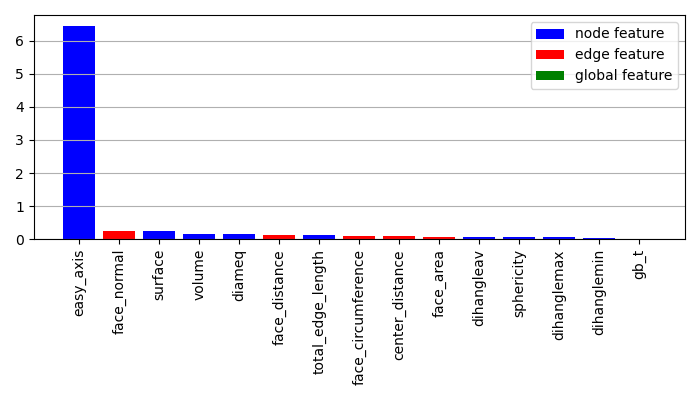

In [6]:

_s = sa_test.scores
def _color(f: str):
    if f in test_ds.node_feature_map:
        return "blue"
    elif f in test_ds.edge_feature_map:
        return "red"
    elif f in test_ds.global_feature_map:
        return "green"
    else:
        raise ValueError
label_map = {"blue": "node feature", "red": "edge feature", "green": "global feature"}
colors = [_color(f) for f in _s]

seen = set()
color_labels = []

for c in colors:
    item = label_map[c]
    if item in seen:
        color_labels.append(f"_{item}")
    else:
        color_labels.append(item)
        seen.add(item)


plt.figure(figsize=(7, 4))
plt.bar(list(_s.keys()), list(_s.values()), color=colors, label=color_labels)
plt.legend()
plt.xticks(rotation=90)
plt.grid(True, axis="y")
#plt.yscale("log")
plt.tight_layout()
plt.savefig("bhmax_saliency_score.pdf")


In [7]:
from micromagnetic_gnn.trainer import opt_easy_axis

data_raw = [d.to("cuda") for d in test_ds]
data_opt = [opt_easy_axis(model.to("cuda"), d.clone().to("cuda"), lr=1e-3, steps=1500) for d in data_raw]

In [8]:
_ea = torch.stack([torch.mean(d.x[:, :3] @ torch.tensor([0, 0, 1.0]).to("cuda"))
       for d in data_opt])

sa_test_opt = saliency_analysis(model, data_opt)
_ea.mean()


tensor(0.9992, device='cuda:0', grad_fn=<MeanBackward0>)

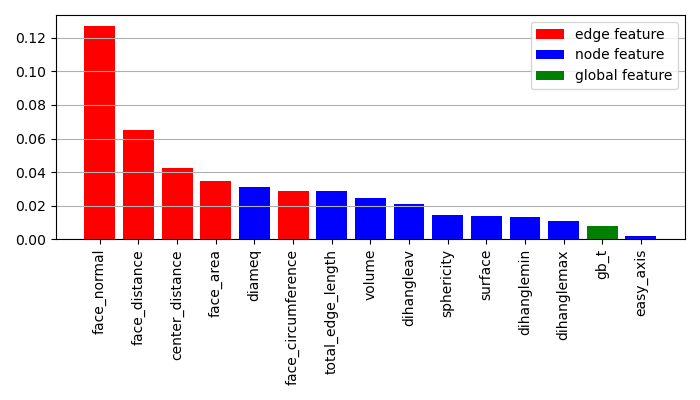

In [9]:

_s = sa_test_opt.scores
def _color(f: str):
    if f in test_ds.node_feature_map:
        return "blue"
    elif f in test_ds.edge_feature_map:
        return "red"
    elif f in test_ds.global_feature_map:
        return "green"
    else:
        raise ValueError
label_map = {"blue": "node feature", "red": "edge feature", "green": "global feature"}
colors = [_color(f) for f in _s]

seen = set()
color_labels = []

for c in colors:
    item = label_map[c]
    if item in seen:
        color_labels.append(f"_{item}")
    else:
        color_labels.append(item)
        seen.add(item)


plt.figure(figsize=(7, 4))
plt.bar(list(_s.keys()), list(_s.values()), color=colors, label=color_labels)
plt.legend()
plt.xticks(rotation=90)
plt.grid(True, axis="y")
#plt.yscale("log")
plt.tight_layout()
plt.savefig("bhmax_saliency_score_opt.pdf")


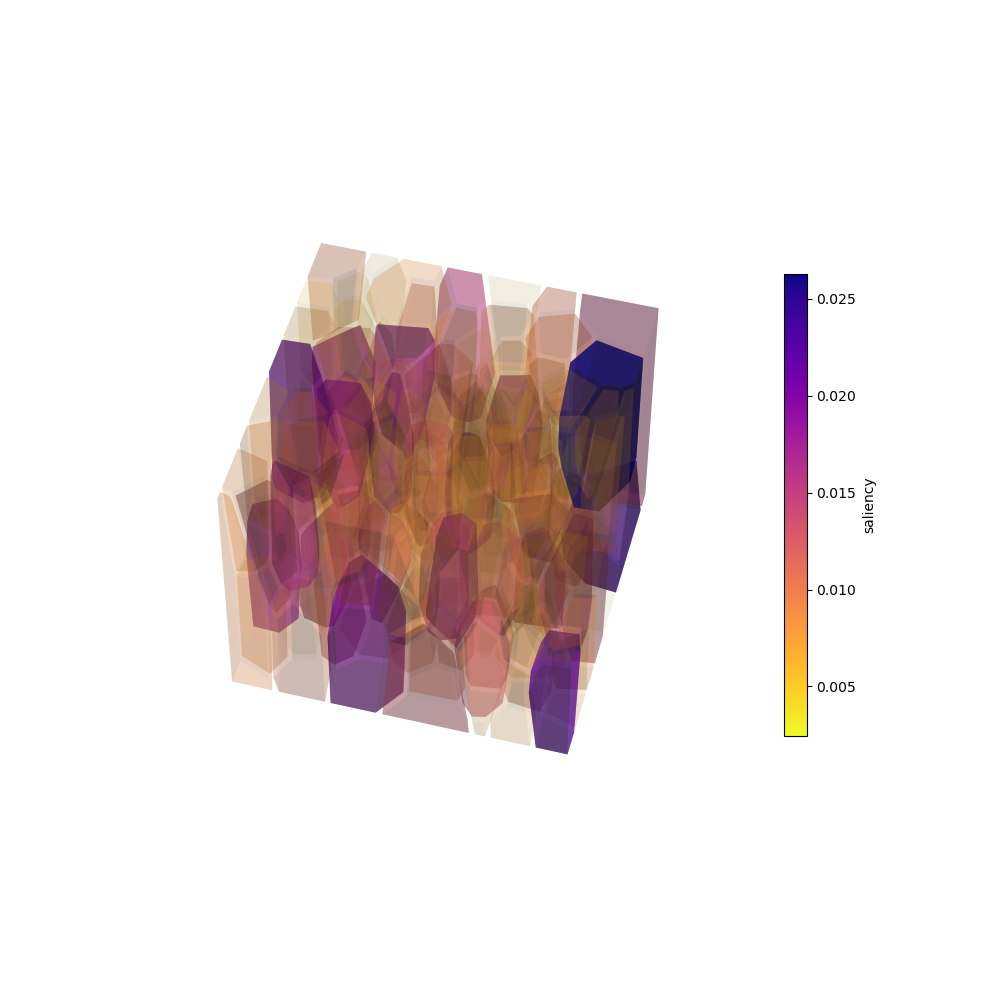

In [10]:
from micromagnetic_gnn.plotting import draw_grain_structure
gs_index = 25
gs = gs_test[gs_index]

score = np.asarray(sa_test.saliency_maps[gs_index].total_node_saliency.detach().to("cpu"))

draw_grain_structure(gs, score, score, cbar_label="saliency");
plt.gca().view_init(elev=50, azim=15, roll=0)
plt.savefig("bhmax_saliency_map.pdf")

In [11]:
from micromagnetic_gnn.trainer import opt_easy_axis, easy_axis_grad


d = test_ds[gs_index]
d = opt_easy_axis(model, d.to("cuda"), lr=1e-3, steps=2000)

In [12]:
d = d.clone().to("cuda")
ea = d.x[:, d.node_feature_map["easy_axis"]].clone()
easy_axis_grad(ea, d, model).norm()

tensor(4.9116e-06, device='cuda:0', grad_fn=<LinalgVectorNormBackward0>)

In [13]:
from micromagnetic_gnn.explain import saliency
sd = saliency(model, d.clone())

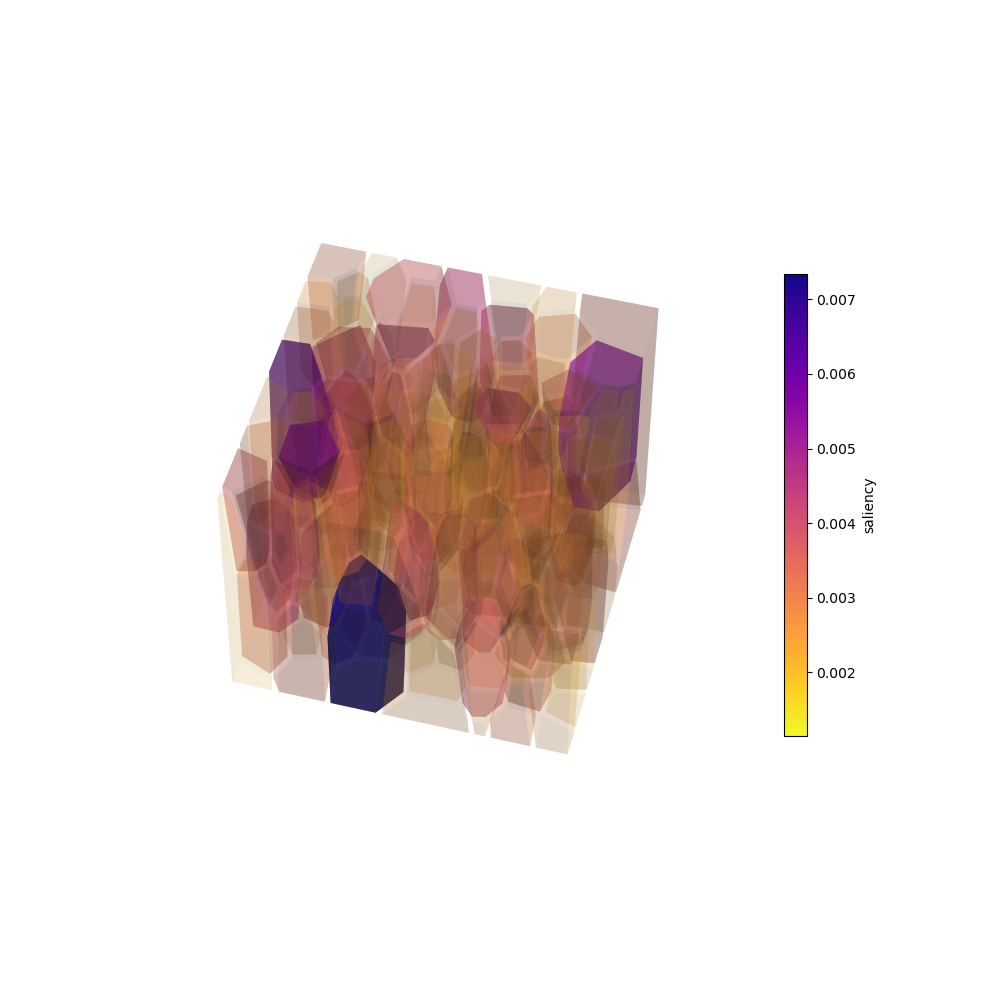

In [14]:

score = np.asarray(sd.total_node_saliency.detach().to("cpu"))

draw_grain_structure(gs, score, score, cbar_label="saliency");
plt.gca().view_init(elev=50, azim=15, roll=0)
plt.savefig("bhmax_saliency_map_opt.pdf")